# 08 · Análise da Wav-KAN: tabela, contrastes pré-registrados e frase

**Sessão P3 · CPU** (Colab sem GPU, ou localmente). Lê `resultados/ablacao_cabeca` e `resultados/mlsd_cabeca` (cabeças (a)–(d) do P1), `resultados/wavkan` e `resultados/wavkan_mlsd` (W1–W5 do `07`) e `resultados/benchmark_cabecas.json` (do `06`). Confere a integridade, **recalcula as métricas a partir dos `pred_teste.csv`**, faz o bootstrap pareado e aplica a regra abaixo.

## Regra pré-registrada (plano P3 de 14/10/2026, com os ajustes de 19/10/2026 das notas do P1, §7–8 — fixada antes de qualquer rodada da Wav-KAN)

* **Métrica primária:** AUC (de probabilidades), média entre as 5 dobras. F1 macro é secundária.
* **Pareamento:** cada contraste usa só as sementes que os dois lados têm completas (5 dobras). Por imagem, a probabilidade é a média dessas sementes (como no 05/05b). IC 95 % por bootstrap pareado de **casos** (2.000 reamostragens) sobre o OOF, que tem as mesmas imagens dos dois lados. Por dobra, a métrica é a média das sementes.
* **Contraste primário 1 — W2 × MLP-128 (b)**, mesmo orçamento (Δ = −62 parâmetros):
  * **superior** = ΔAUC > 0 em ≥ 4/5 dobras **e** IC 95 % do ΔAUC acima de 0 → só então "*more parameter-efficient than an MLP*";
  * **inferior** = ΔAUC > 0 em ≤ 1/5 dobras **e** IC 95 % abaixo de 0;
  * **empate** ("*on par with an MLP of equal size*") = nem superior nem inferior, com não inferioridade (abaixo);
  * senão, **inconclusivo**.
* **Contraste primário 2 — W1 e W5 × MLP-iso (c):** não inferioridade com **margem −0,02**: limite inferior do IC 95 % do ΔAUC **e** do ΔF1 acima de −0,02. Reporta também as dobras em que W não perde.
* **Contraste secundário — W1, W2 e W5 × KAN spline (d):** não inferioridade com a mesma margem (era o primário em 14/10; o P1 mostrou que (d) empata com as MLPs, então ele deixou de ser a referência que mais informa).
* **Sensibilidade:** W3 (DoG) e W4 (Morlet) × W1 e W5 só com a semente 42; não geram afirmações próprias.
* **MLSD:** W2 × (b), W1 × (c) e W1/W2 × (d), com as mesmas regras.
* **Tempo:** "mais rápida" só se o tempo só da cabeça na L4 (`06`, fwd+bwd com lote 32) for menor além do ruído (média + dp < média − dp do rival) **e** o tempo por dobra medido nas rodadas (15·t_F1 + 45·t_F2) também cair. "Mais lenta" se o tempo por dobra subir além do ruído (média − dp > média + dp do rival). Se a diferença por dobra couber no ruído: "*fewer head parameters at equal wall-clock time*", sempre com a ressalva de que o backbone domina o custo. Se a dobra encurtar sem a cabeça ser mais rápida: "indefinido" (variação entre máquinas), sem frase de tempo.
* **Proibido:** comparar com 0,908 (TCC antigo) ou 0,893 (artigo do SIBGRAPI); falar em *parameter efficiency* sem o contraste 1 dar "superior"; dizer que a KAN spline é "a referência que funciona".

Saídas em `resultados/`: `tabela_wavkan.{csv,tex}` (E/S), `tabela_wavkan_mlsd.{csv,tex}`, `contrastes_wavkan.{csv,tex}`, `decisao_wavkan.json`, `frases_wavkan.md`, `fig_auc_vs_parametros.pdf` e `diagnostico_wavkan.csv`.

In [1]:
# ==== Configuração ====
NO_COLAB = True    # False para rodar localmente (aponte os caminhos abaixo para cópias locais)
DIR_DRIVE = "/content/drive/MyDrive/Colab Notebooks/tcc-final"
DIR_CODIGO = DIR_DRIVE                       # protocolo_comum.py, configs_mlsd.py e cabecas_wavkan.py (localmente: notebooks/)
DIR_RESULTADOS = f"{DIR_DRIVE}/resultados"   # localmente: uma cópia da pasta resultados/ do Drive
SHA_PROTOCOLO_ESPERADO = "b7cd9baca53edd96c855cca10914fc258efa8ddfd0937cc0d3e9572de5ef9e13"
SHA_PLUGIN_ESPERADO = "d02f6ca6f41f0530df0f0cc3886382a8c35311ac1ec812c1f65fa74e18d800ed"   # cabecas_wavkan.py
SHA_MLSD_ESPERADO = "e2138640a83ef7587200ad6e051262b6a49e5b60027f6b4a61407fd1f61889f7"     # configs_mlsd.py
N_BOOT = 2000
MARGEM_NI = -0.02   # margem de não inferioridade pré-registrada (ΔAUC e ΔF1)

In [2]:
if NO_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")

Mounted at /content/drive


In [3]:
import sys, json
from pathlib import Path
import numpy as np, pandas as pd
from sklearn.metrics import (roc_auc_score, accuracy_score, precision_score, recall_score, f1_score,
                             balanced_accuracy_score)
sys.path.insert(0, DIR_CODIGO)
import protocolo_comum as pc
assert pc.sha256_protocolo() == SHA_PROTOCOLO_ESPERADO, "protocolo_comum.py diferente do publicado"
for _arq, _sha in (("cabecas_wavkan.py", SHA_PLUGIN_ESPERADO), ("configs_mlsd.py", SHA_MLSD_ESPERADO)):
    assert pc.sha256_arquivo(f"{DIR_CODIGO}/{_arq}") == _sha, f"{_arq} diferente do publicado"
    pc.carregar_plugin(f"{DIR_CODIGO}/{_arq}")
cw, cm = sys.modules["cabecas_wavkan"], sys.modules["configs_mlsd"]
R = Path(DIR_RESULTADOS)
TAREFAS = ("es", "dist")
ROTULO = {"es": "entrada/saída", "dist": "MLSD (distância)"}
TASK_EN = {"es": "entry/exit classification", "dist": "shooting-distance (MLSD) classification"}
EXP_REF = {"es": "ablacao_cabeca", "dist": "mlsd_cabeca"}
REFS = {"es": {k: pc.CONFIGS_EXP1[k] for k in "abcd"}, "dist": {k: cm.CONFIGS_CABECA[k] for k in "abcd"}}
WS = {"es": dict(cw.CONFIGS_ES), "dist": dict(cw.CONFIGS_MLSD)}
ID = {t: {**{v: k for k, v in REFS[t].items()}, **{v: k for k, v in WS[t].items()}} for t in TAREFAS}
CFG = {t: {v: k for k, v in ID[t].items()} for t in TAREFAS}          # id -> config
ORDEM = ["a", "b", "c", "d", "W1", "W2", "W3", "W4", "W5"]
NOMES = {"a": "ResNet152 + Linear (a)", "b": "ResNet152 + MLP-128 (b)", "c": "ResNet152 + MLP-iso (c)",
         "d": "ResNet152 + KAN spline (d) = TransKAN",
         "W1": "ResNet152 + Wav-KAN mexican hat, h=128 (W1)", "W2": "ResNet152 + Wav-KAN mexican hat, h=32 (W2)",
         "W3": "ResNet152 + Wav-KAN DoG, h=128 (W3)", "W4": "ResNet152 + Wav-KAN Morlet, h=128 (W4)",
         "W5": "ResNet152 + Wav-KAN mexican hat, h=480 (W5)"}
SEMENTES_PLANO = {"W1": [42, 43, 44], "W2": [42, 43, 44], "W3": [42], "W4": [42], "W5": [42]}

def ler(exp):
    r = pc.ler_resultados(R, exp)
    return r[~r["teste_rapido"].astype(bool)].copy() if len(r) else r

runs = {}
for t in TAREFAS:
    partes = [x for x in (ler(EXP_REF[t]), ler(cw.EXPERIMENTO[t])) if len(x)]
    r = pd.concat(partes, ignore_index=True) if partes else pd.DataFrame(columns=["config"])
    r = r[r["config"].isin(ID[t])].copy()
    r["id"] = r["config"].map(ID[t])
    runs[t] = r
    print(f"{ROTULO[t]}: {len(r)} unidades")
    if len(r):
        display(r.groupby(["id", "semente"]).size().rename("dobras").unstack("semente"))
arq_b = R / "benchmark_cabecas.json"
bench = json.loads(arq_b.read_text()) if arq_b.exists() else {}
if not bench:
    print("⚠️ Sem benchmark_cabecas.json (rode o 06): as colunas de tempo só da cabeça ficam vazias.")
elif bench.get("plugin_sha256") != SHA_PLUGIN_ESPERADO:
    print("⚠️ benchmark_cabecas.json é de outra versão do plugin.")

entrada/saída: 105 unidades


semente,42,43,44
id,,,
W1,5.0,5.0,5.0
W2,5.0,5.0,5.0
W3,5.0,NaN,NaN
W4,5.0,NaN,NaN
W5,5.0,NaN,NaN
a,5.0,5.0,5.0
b,5.0,5.0,5.0
c,5.0,5.0,5.0
d,5.0,5.0,5.0


MLSD (distância): 88 unidades


semente,42,43,44
id,,,
W1,5,5,5
W2,5,5,3
a,5,5,5
b,5,5,5
c,5,5,5
d,5,5,5


## 1. Integridade (hashes, GPU, sementes completas, métricas recalculadas das predições, mesmas imagens)

In [4]:
def prob_cols(t):
    return [f"p_{t}_{c}" for c in range(pc.TAREFAS[t].n_classes)]

def auc_tarefa(y, P):
    if P.shape[1] == 2:
        return roc_auc_score(y, P[:, 1])
    return roc_auc_score(y, P, multi_class="ovr", average="macro", labels=list(range(P.shape[1])))

problemas, avisos = [], []
for t in TAREFAS:
    runs[t]["reserva"] = ~runs[t]["gpu"].fillna("").str.contains("L4")
todos = pd.concat([runs[t] for t in TAREFAS if len(runs[t])], ignore_index=True)
for col in ("protocolo_sha256", "dobras_sha256", "precisao"):
    vals = todos[col].dropna().unique()
    if len(vals) != 1:
        problemas.append(f"{col} não é único: {vals}")
if todos["protocolo_sha256"].iloc[0] != SHA_PROTOCOLO_ESPERADO:
    problemas.append("SHA do protocolo diferente do publicado")
for t in TAREFAS:
    for _, r in runs[t][runs[t]["id"].str.startswith("W")].iterrows():
        pl = json.loads(r["plugins"])
        if pl.get("cabecas_wavkan") != SHA_PLUGIN_ESPERADO:
            problemas.append(f"{r['config']} s{r['semente']} d{r['dobra']}: rodou com outro cabecas_wavkan.py")
        if t == "dist" and pl.get("configs_mlsd") != SHA_MLSD_ESPERADO:
            problemas.append(f"{r['config']} s{r['semente']} d{r['dobra']}: rodou com outro configs_mlsd.py")
    for f in ((R / cw.EXPERIMENTO[t]).rglob("falha_nan.json") if (R / cw.EXPERIMENTO[t]).exists() else []):
        problemas.append(f"perda NaN registrada em {f.parent}")
for p in sorted(R.iterdir()):
    if p.is_dir() and p.name.startswith("wavkan") and p.name not in ("wavkan", "wavkan_mlsd"):
        avisos.append(f"pasta {p.name!r} em resultados/: confira no Drive se não é uma cópia duplicada")
if todos["reserva"].any():
    print("† unidades fora da L4:")
    display(todos.loc[todos.reserva].groupby(["experimento", "config", "semente"]).size())

# sementes completas (5 dobras) por config; o resto fica fora da análise, com aviso
SEM, incompletas = {t: {} for t in TAREFAS}, []
for t in TAREFAS:
    keep = []
    for (cfg, s), g in runs[t].groupby(["config", "semente"]):
        if sorted(g["dobra"]) == list(range(pc.N_DOBRAS)):
            SEM[t].setdefault(cfg, []).append(int(s)); keep.append(g)
        else:
            incompletas.append(f"{ROTULO[t]} {ID[t][cfg]} s{s}: dobras {sorted(g['dobra'])}")
    runs[t] = pd.concat(keep, ignore_index=True) if keep else runs[t].iloc[0:0]
    for w, sems in SEMENTES_PLANO.items():
        falta = sorted(set(sems) - set(SEM[t].get(WS[t][w], []))) if w in WS[t] else []
        if falta:
            avisos.append(f"{ROTULO[t]} {w}: sementes ainda não concluídas {falta}")
if incompletas:
    avisos.append("sementes incompletas (fora da análise): " + "; ".join(incompletas))

OOF = {t: [] for t in TAREFAS}
for t in TAREFAS:
    col = pc.TAREFAS[t].coluna
    for _, r in runs[t].iterrows():
        p = pd.read_csv(Path(r["caminho"]) / "pred_teste.csv")
        v = p[p[col] >= 0]
        y, P = v[col].to_numpy(), v[prob_cols(t)].to_numpy()
        pred = P.argmax(1)
        rec = {f"{t}_acc": accuracy_score(y, pred), f"{t}_auc": auc_tarefa(y, P),
               f"{t}_rec_macro": recall_score(y, pred, average="macro"),
               f"{t}_prec_macro": precision_score(y, pred, average="macro", zero_division=0),
               f"{t}_f1_macro": f1_score(y, pred, average="macro"),
               f"{t}_acc_balanceada": balanced_accuracy_score(y, pred)}
        for k, val in rec.items():
            if abs(val - r[k]) > 1e-9:
                problemas.append(f"{r['config']} s{r['semente']} d{r['dobra']}: {k} recalculado {val} ≠ {r[k]}")
        if abs(r[f"{t}_auc"] - r[f"{t}_rec_macro"]) < 1e-12:
            avisos.append(f"{r['config']} s{r['semente']} d{r['dobra']}: AUC = revocação macro (modelo degenerado?)")
        OOF[t].append(v.assign(config=r["config"], id=r["id"], semente=r["semente"], dobra=r["dobra"]))
    OOF[t] = pd.concat(OOF[t], ignore_index=True) if OOF[t] else pd.DataFrame()
    # mesmas imagens por dobra entre W e (d)
    if len(OOF[t]) and REFS[t]["d"] in SEM[t]:
        ref = OOF[t][OOF[t].config == REFS[t]["d"]].groupby("dobra")["rel_path"].apply(frozenset)
        for (cfg, s, d), g in OOF[t][OOF[t].id.str.startswith("W")].groupby(["config", "semente", "dobra"]):
            if frozenset(g["rel_path"]) != ref.get(d):
                problemas.append(f"{cfg} s{s} d{d}: imagens de teste diferentes das de (d)")
print("Problemas:", problemas or "nenhum")
print("Avisos:", avisos or "nenhum")
assert not problemas

Problemas: nenhum
Avisos: ['MLSD (distância) W2: sementes ainda não concluídas [44]', 'sementes incompletas (fora da análise): MLSD (distância) W2 s44: dobras [0, 1, 2]']


## 2. Média ± dp entre dobras (cada dobra = média das sementes completas)

In [5]:
def resumir(t):
    r = runs[t].copy()
    if r.empty:
        return pd.DataFrame()
    r["tempo_dobra_min"] = (pc.RECEITA["epocas_f1"] * r["f1_s_epoca"] + pc.RECEITA["epocas_f2"] * r["f2_s_epoca"]) / 60
    metr = [f"{t}_{m}" for m in ("acc", "prec_macro", "rec_macro", "f1_macro", "acc_balanceada", "auc")]
    por_dobra = r.groupby(["id", "dobra"])[metr].mean().reset_index()
    agg = por_dobra.groupby("id")[metr].agg(["mean", "std", "count"])
    agg.columns = [f"{a}_{b}" for a, b in agg.columns]
    l4 = r[~r["reserva"]]
    tempo = l4.groupby("id")["tempo_dobra_min"].agg(["mean", "std"]).rename(columns=lambda c: f"tempo_dobra_min_{c}")
    info = r.groupby("id").agg(params_cabeca=("params_cabeca", "first"), params_total=("params_total", "first"),
                               reserva=("reserva", "any"), treino_min=("treino_min", "mean"))
    info["sementes"] = r.groupby("id")["semente"].apply(lambda s: sorted(set(int(x) for x in s)))
    auc_oof = {}
    for i, g in OOF[t].groupby("id"):
        o = g.groupby(["rel_path", pc.TAREFAS[t].coluna])[prob_cols(t)].mean().reset_index()
        auc_oof[i] = auc_tarefa(o[pc.TAREFAS[t].coluna].to_numpy(), o[prob_cols(t)].to_numpy())
    out = agg.join(tempo).join(info)
    out["auc_oof"] = pd.Series(auc_oof)
    return out.loc[[i for i in ORDEM if i in out.index]]

RES = {t: resumir(t) for t in TAREFAS}
for t in TAREFAS:
    if len(RES[t]):
        print(ROTULO[t])
        display(RES[t][[f"{t}_auc_mean", f"{t}_auc_std", "auc_oof", f"{t}_f1_macro_mean", f"{t}_f1_macro_std",
                        "tempo_dobra_min_mean", "params_cabeca", "sementes"]].round(4))

entrada/saída


,es_auc_mean,es_auc_std,auc_oof,es_f1_macro_mean,es_f1_macro_std,tempo_dobra_min_mean,params_cabeca,sementes
id,,,,,,,,
a,0.9041,0.0131,0.9054,0.8054,0.0116,8.2458,4098,"[42, 43, 44]"
b,0.9050,0.0137,0.9062,0.8058,0.0148,8.2730,262530,"[42, 43, 44]"
c,0.9057,0.0138,0.9072,0.8071,0.0127,8.3502,3935871,"[42, 43, 44]"
d,0.9050,0.0134,0.9061,0.8060,0.0134,8.4876,3936000,"[42, 43, 44]"
W1,0.9017,0.0141,0.9055,0.7999,0.0189,8.7929,1049860,"[42, 43, 44]"
W2,0.9018,0.0130,0.9053,0.7989,0.0217,8.4578,262468,"[42, 43, 44]"
W3,0.9077,0.0146,0.9072,0.7933,0.0261,8.6643,1049860,[42]
W4,0.9010,0.0153,0.9003,0.7788,0.0279,8.7166,1049860,[42]
W5,0.9035,0.0132,0.9025,0.7987,0.0220,10.6009,3936964,[42]


MLSD (distância)


,dist_auc_mean,dist_auc_std,auc_oof,dist_f1_macro_mean,dist_f1_macro_std,tempo_dobra_min_mean,params_cabeca,sementes
id,,,,,,,,
a,0.7846,0.0872,0.7975,0.4884,0.0559,6.2993,6147,"[42, 43, 44]"
b,0.8015,0.0621,0.8106,0.4821,0.0505,6.3090,262659,"[42, 43, 44]"
c,0.8069,0.0550,0.8167,0.4799,0.0497,6.3581,3937791,"[42, 43, 44]"
d,0.7977,0.0575,0.8054,0.4771,0.0451,6.4603,3937920,"[42, 43, 44]"
W1,0.7111,0.1155,0.7303,0.4183,0.0337,6.7348,1050374,"[42, 43, 44]"
W2,0.7131,0.1121,0.7334,0.4102,0.0354,6.4701,262598,"[42, 43]"


## 3. Contrastes pareados (bootstrap de casos) e regra pré-registrada

In [6]:
def f1_macro_rapido(y, pred, k):
    cmx = np.bincount(y * k + pred, minlength=k * k).reshape(k, k)
    tp = np.diag(cmx); den = 2 * tp + (cmx.sum(0) - tp) + (cmx.sum(1) - tp)
    return float(np.where(den > 0, 2 * tp / np.maximum(den, 1), 0.0).mean())

def oof_medio(t, cfg, sementes):
    col = pc.TAREFAS[t].coluna
    o = OOF[t][(OOF[t].config == cfg) & OOF[t].semente.isin(sementes)]
    return o.groupby(["rel_path", "case_id", col, "dobra"])[prob_cols(t)].mean().reset_index().set_index("rel_path")

def comparar(t, id_a, id_b, n_boot=N_BOOT, semente=0):
    # Δ (a − b): AUC e F1 macro no OOF (média das sementes comuns), IC 95 % por bootstrap de casos, e por dobra.
    cfg_a, cfg_b = CFG[t][id_a], CFG[t][id_b]
    sem = sorted(set(SEM[t].get(cfg_a, [])) & set(SEM[t].get(cfg_b, [])))
    if not sem:
        return None
    col, k = pc.TAREFAS[t].coluna, pc.TAREFAS[t].n_classes
    a, b = oof_medio(t, cfg_a, sem), oof_medio(t, cfg_b, sem)
    assert set(a.index) == set(b.index), f"{id_a} × {id_b}: OOF com imagens diferentes"
    b = b.loc[a.index]
    y = a[col].to_numpy().astype(int)
    Pa, Pb = a[prob_cols(t)].to_numpy(), b[prob_cols(t)].to_numpy()
    pa, pb = Pa.argmax(1), Pb.argmax(1)
    d_auc = auc_tarefa(y, Pa) - auc_tarefa(y, Pb)
    d_f1 = f1_macro_rapido(y, pa, k) - f1_macro_rapido(y, pb, k)
    casos = a["case_id"].to_numpy()
    uc = np.unique(casos)
    idx_caso = {c: np.flatnonzero(casos == c) for c in uc}
    rng = np.random.default_rng(semente)
    b_auc, b_f1 = [], []
    for _ in range(n_boot):
        am = np.concatenate([idx_caso[c] for c in rng.choice(uc, size=len(uc), replace=True)])
        try:
            da = auc_tarefa(y[am], Pa[am]) - auc_tarefa(y[am], Pb[am])
        except ValueError:      # reamostra sem alguma classe
            continue
        b_auc.append(da)
        b_f1.append(f1_macro_rapido(y[am], pa[am], k) - f1_macro_rapido(y[am], pb[am], k))
    r = runs[t][runs[t].semente.isin(sem)]
    pdob = r.groupby(["id", "dobra"])[[f"{t}_auc", f"{t}_f1_macro"]].mean()
    dd = (pdob.loc[id_a] - pdob.loc[id_b]).dropna()
    return {"tarefa": t, "a": id_a, "b": id_b, "sementes": sem,
            "delta_auc_oof": float(d_auc), "ic95_auc": [float(x) for x in np.percentile(b_auc, [2.5, 97.5])],
            "delta_f1_oof": float(d_f1), "ic95_f1": [float(x) for x in np.percentile(b_f1, [2.5, 97.5])],
            "n_boot_validos": len(b_auc),
            "delta_auc_dobras": {int(i): round(float(v), 4) for i, v in dd[f"{t}_auc"].items()},
            "delta_f1_dobras": {int(i): round(float(v), 4) for i, v in dd[f"{t}_f1_macro"].items()},
            "media_delta_auc_dobras": float(dd[f"{t}_auc"].mean()),
            "dp_delta_auc_dobras": float(dd[f"{t}_auc"].std(ddof=1)) if len(dd) > 1 else None,
            "dobras_a_vence": int((dd[f"{t}_auc"] > 0).sum()), "dobras_a_nao_perde": int((dd[f"{t}_auc"] >= 0).sum()),
            "n_dobras": int(len(dd))}

def avaliar(c):
    sup = c["dobras_a_vence"] >= 4 and c["ic95_auc"][0] > 0
    inf = c["dobras_a_vence"] <= 1 and c["ic95_auc"][1] < 0
    ni = c["ic95_auc"][0] > MARGEM_NI and c["ic95_f1"][0] > MARGEM_NI
    c.update(superior=bool(sup), inferior=bool(inf), nao_inferior=bool(ni))
    return c

PLANO = {
    "es": [("W2", "b", "primário 1"), ("W1", "c", "primário 2"), ("W5", "c", "primário 2"),
           ("W1", "d", "secundário"), ("W2", "d", "secundário"), ("W5", "d", "secundário"),
           ("W1", "b", "descritivo"), ("W3", "W1", "sensibilidade"), ("W4", "W1", "sensibilidade"),
           ("W3", "d", "sensibilidade"), ("W4", "d", "sensibilidade")],
    "dist": [("W2", "b", "primário 1"), ("W1", "c", "primário 2"),
             ("W1", "d", "secundário"), ("W2", "d", "secundário"), ("W1", "b", "descritivo")],
}
COMP, linhas = {}, []
for t in TAREFAS:
    for a, b, papel in PLANO[t]:
        if a not in CFG[t] or b not in CFG[t]:
            continue
        c = comparar(t, a, b)
        if c is None:
            continue
        c = avaliar(c); c["papel"] = papel
        COMP[f"{t}__{a}_vs_{b}"] = c
        linhas.append({"tarefa": t, "contraste": f"{a} − {b}", "papel": papel, "sementes": ",".join(map(str, c["sementes"])),
                       "ΔAUC OOF": round(c["delta_auc_oof"], 4), "IC95 AUC": [round(x, 4) for x in c["ic95_auc"]],
                       "ΔF1 OOF": round(c["delta_f1_oof"], 4), "IC95 F1": [round(x, 4) for x in c["ic95_f1"]],
                       "W vence (dobras)": f"{c['dobras_a_vence']}/{c['n_dobras']}",
                       "W não perde (dobras)": f"{c['dobras_a_nao_perde']}/{c['n_dobras']}",
                       "superior": c["superior"], "inferior": c["inferior"], "não inferior": c["nao_inferior"]})
TAB_C = pd.DataFrame(linhas)
display(TAB_C)

DESFECHO = {}
for t in TAREFAS:
    c = COMP.get(f"{t}__W2_vs_b")
    if c is None:
        continue
    d = "A" if c["superior"] else ("C" if c["inferior"] else ("B" if c["nao_inferior"] else "inconclusivo"))
    DESFECHO[t] = d
    print(f"{ROTULO[t]} — contraste primário 1 (W2 × MLP-128): desfecho {d} "
          f"(ΔAUC {c['delta_auc_oof']:+.4f}, IC95 [{c['ic95_auc'][0]:+.4f}, {c['ic95_auc'][1]:+.4f}]; "
          f"W2 vence em {c['dobras_a_vence']}/{c['n_dobras']} dobras; sementes {c['sementes']})")

,tarefa,contraste,papel,sementes,ΔAUC OOF,IC95 AUC,ΔF1 OOF,IC95 F1,W vence (dobras),W não perde (dobras),superior,inferior,não inferior
0,es,W2 − b,primário 1,"42,43,44",-0.0009,"[-0.0039, 0.0022]",-0.0124,"[-0.023, -0.0026]",0/5,0/5,False,False,False
1,es,W1 − c,primário 2,"42,43,44",-0.0017,"[-0.005, 0.0017]",-0.0025,"[-0.0142, 0.0082]",0/5,0/5,False,False,True
2,es,W5 − c,primário 2,42,-0.0031,"[-0.0079, 0.0016]",-0.0085,"[-0.0194, 0.0026]",2/5,2/5,False,False,True
3,es,W1 − d,secundário,"42,43,44",-0.0007,"[-0.004, 0.0028]",-0.0055,"[-0.016, 0.005]",1/5,1/5,False,False,True
4,es,W2 − d,secundário,"42,43,44",-0.0008,"[-0.0034, 0.0018]",-0.0109,"[-0.0206, -0.0018]",0/5,0/5,False,False,False
5,es,W5 − d,secundário,42,-0.0017,"[-0.0066, 0.0032]",-0.0084,"[-0.0195, 0.0025]",2/5,2/5,False,False,True
6,es,W1 − b,descritivo,"42,43,44",-0.0008,"[-0.0043, 0.0028]",-0.0070,"[-0.0191, 0.0044]",1/5,1/5,False,False,True
7,es,W3 − W1,sensibilidade,42,0.0025,"[-0.0018, 0.0064]",-0.0081,"[-0.018, 0.001]",4/5,4/5,False,False,True
8,es,W4 − W1,sensibilidade,42,-0.0044,"[-0.0096, 0.0009]",-0.0227,"[-0.0347, -0.0117]",1/5,1/5,False,False,False
9,es,W3 − d,sensibilidade,42,0.0031,"[-0.0013, 0.0073]",-0.0137,"[-0.0266, -0.0009]",4/5,4/5,False,False,False


entrada/saída — contraste primário 1 (W2 × MLP-128): desfecho inconclusivo (ΔAUC -0.0009, IC95 [-0.0039, +0.0022]; W2 vence em 0/5 dobras; sementes [42, 43, 44])
MLSD (distância) — contraste primário 1 (W2 × MLP-128): desfecho C (ΔAUC -0.0765, IC95 [-0.1033, -0.0495]; W2 vence em 0/5 dobras; sementes [42, 43])


## 4. Tempo: cabeça (06) e dobra inteira (rodadas)

In [7]:
SO_CAB = pd.DataFrame(bench.get("so_cabeca", []))
if len(SO_CAB):
    SO_CAB = SO_CAB[~SO_CAB["compile"].astype(bool)]
def cab(id_, modo="fwd_bwd", lote=32):
    if SO_CAB.empty:
        return None
    x = SO_CAB[(SO_CAB.cabeca == id_) & (SO_CAB.modo == modo) & (SO_CAB.lote == lote)]
    return x.iloc[0] if len(x) else None

def tempo(t, a, b):
    ca, cb = cab(a), cab(b)
    ra, rb = RES[t].loc[a] if a in RES[t].index else None, RES[t].loc[b] if b in RES[t].index else None
    if ca is None or cb is None or ra is None or rb is None:
        return None
    cab_rapida = ca.ms_media + ca.ms_dp < cb.ms_media - cb.ms_dp
    ma, sa, mb, sb = ra.tempo_dobra_min_mean, ra.tempo_dobra_min_std, rb.tempo_dobra_min_mean, rb.tempo_dobra_min_std
    sa, sb = (0 if pd.isna(sa) else sa), (0 if pd.isna(sb) else sb)
    if cab_rapida and ma < mb:
        desf = "mais_rapida"
    elif ma - sa > mb + sb:
        desf = "mais_lenta"
    elif abs(ma - mb) <= sa + sb:
        desf = "igual"
    else:
        desf = "indefinido"   # dobra mais curta sem cabeça mais rápida: variação entre máquinas
    return {"tarefa": t, "a": a, "b": b, "desfecho": desf,
            "cabeca_ms_lote32": [float(ca.ms_media), float(ca.ms_dp), float(cb.ms_media), float(cb.ms_dp)],
            "cabeca_mais_rapida_alem_do_ruido": bool(cab_rapida),
            "min_por_dobra": [float(ma), float(sa), float(mb), float(sb)], "variacao_dobra_pct": float(100 * (ma / mb - 1)),
            "razao_params_cabeca": float(rb.params_cabeca / ra.params_cabeca)}

TEMPO = {}
for t in TAREFAS:
    for a, b in (("W2", "b"), ("W1", "c"), ("W5", "c"), ("W1", "d"), ("W2", "d"), ("W5", "d")):
        x = tempo(t, a, b)
        if x:
            TEMPO[f"{t}__{a}_vs_{b}"] = x
display(pd.DataFrame(TEMPO.values()).round(3) if TEMPO else "sem dados de tempo ainda")

,tarefa,a,b,desfecho,cabeca_ms_lote32,cabeca_mais_rapida_alem_do_ruido,min_por_dobra,variacao_dobra_pct,razao_params_cabeca
0,es,W2,b,igual,"[2.9521865606307984, 0.1351113428943226, 0.728...",False,"[8.45780888888889, 0.1049648998147558, 8.27297...",2.234,1.000
1,es,W1,c,mais_lenta,"[8.838018565177917, 0.05250032005500807, 0.734...",False,"[8.79289, 0.10291240396030411, 8.35016, 0.1137...",5.302,3.749
2,es,W5,c,mais_lenta,"[38.35701896667481, 0.03655098025652635, 0.734...",False,"[10.60086, 0.11357016590343394, 8.35016, 0.113...",26.954,1.000
3,es,W1,d,mais_lenta,"[8.838018565177917, 0.05250032005500807, 3.296...",False,"[8.79289, 0.10291240396030411, 8.4876433333333...",3.596,3.749
4,es,W2,d,mais_rapida,"[2.9521865606307984, 0.1351113428943226, 3.296...",True,"[8.45780888888889, 0.1049648998147558, 8.48764...",-0.352,14.996
5,es,W5,d,mais_lenta,"[38.35701896667481, 0.03655098025652635, 3.296...",False,"[10.60086, 0.11357016590343394, 8.487643333333...",24.898,1.000
6,dist,W2,b,igual,"[2.9521865606307984, 0.1351113428943226, 0.728...",False,"[6.470141666666666, 0.08983738884888161, 6.309...",2.554,1.000
7,dist,W1,c,mais_lenta,"[8.838018565177917, 0.05250032005500807, 0.734...",False,"[6.734769999999999, 0.09025543034271859, 6.358...",5.924,3.749
8,dist,W1,d,mais_lenta,"[8.838018565177917, 0.05250032005500807, 3.296...",False,"[6.734769999999999, 0.09025543034271859, 6.460...",4.248,3.749
9,dist,W2,d,igual,"[2.9521865606307984, 0.1351113428943226, 3.296...",True,"[6.470141666666666, 0.08983738884888161, 6.460...",0.152,14.996


## 5. Tabelas (CSV + LaTeX)

In [8]:
def pm(m, s, nd=3):
    return f"{m:.{nd}f} ± {s:.{nd}f}" if pd.notna(s) else (f"{m:.{nd}f}" if pd.notna(m) else "")

def tabela(t):
    linhas = []
    for i in ORDEM:
        if i not in CFG[t]:
            continue
        if i not in RES[t].index:
            linhas.append({"id": i, "modelo": NOMES[i], "config": CFG[t][i], "status": "não executado"})
            continue
        r = RES[t].loc[i]
        fb, inf = cab(i), cab(i, "inferencia", 256)
        linhas.append({
            "id": i, "modelo": NOMES[i] + (" †" if r["reserva"] else ""), "config": CFG[t][i], "status": "ok",
            "params_cabeca": int(r["params_cabeca"]), "params_total_M": r["params_total"] / 1e6,
            **{m: pm(r[f"{t}_{m}_mean"], r[f"{t}_{m}_std"]) for m in ("acc", "prec_macro", "rec_macro", "f1_macro", "acc_balanceada", "auc")},
            "auc_oof": round(float(r["auc_oof"]), 4),
            "min_por_dobra": round(float(r["tempo_dobra_min_mean"]), 2) if pd.notna(r["tempo_dobra_min_mean"]) else None,
            "cabeca_fwd_bwd_ms_lote32": round(float(fb.ms_media), 3) if fb is not None else None,
            "cabeca_inferencia_ms_por_img": round(float(inf.ms_por_imagem), 4) if inf is not None else None,
            "cabeca_mem_pico_mb": round(float(fb.mem_pico_mb), 1) if (fb is not None and pd.notna(fb.mem_pico_mb)) else None,
            "sementes": ",".join(map(str, r["sementes"])), "n_dobras": int(r[f"{t}_auc_count"])})
    return pd.DataFrame(linhas)

def tex_pm(s):
    return "$" + s.replace(" ± ", r" \pm ") + "$" if s else "--"

def tex_nome(s):
    return s.replace("_", r"\_").replace("†", r"$^\dagger$")

TAB = {}
for t, arq, rotulo in (("es", "tabela_wavkan", "Entry/exit"), ("dist", "tabela_wavkan_mlsd", "Shooting distance (MLSD, entries only)")):
    TAB[t] = tabela(t)
    TAB[t].to_csv(R / f"{arq}.csv", index=False)
    display(TAB[t])
    sementes_txt = "; ".join(f"{r['id']}: {r['sementes']}" for _, r in TAB[t].iterrows() if r["status"] == "ok")
    tex = [r"\begin{table*}[t]", r"\centering",
           r"\caption{" + rotulo + r": head ablation with wavelet-KAN (Wav-KAN) heads under the single protocol (ResNet-152 "
           r"backbone, grouped stratified 5-fold by case, same two-phase recipe, last epoch). Mean $\pm$ s.d.\ across folds "
           r"(each fold averaged over the training seeds); AUC from predicted probabilities; AUC$_{\mathrm{OOF}}$ pools the "
           r"out-of-fold predictions. Time: minutes per fold on an NVIDIA L4 ($15\,t_{F1}+45\,t_{F2}$); head-only cost on "
           r"random 2048-d inputs: forward+backward for a batch of 32 and inference per image (batch 256). Seeds: " + sementes_txt
           + (r"; $\dagger$ = run on another GPU" if TAB[t]["modelo"].astype(str).str.contains("†").any() else "") + r".}",
           r"\label{tab:wavkan_" + t + "}", r"\scriptsize", r"\setlength{\tabcolsep}{3pt}",
           r"\begin{tabular}{lrrcccccrrrr}", r"\hline",
           r"Head & \multicolumn{2}{c}{Params} & Acc & Prec. & Rec. & F1 & AUC & AUC$_{\mathrm{OOF}}$ & Min/fold & "
           r"Head ms & Head $\mu$s/img \\",
           r" & head & total (M) & & & & & & & & (fwd+bwd) & (inference) \\", r"\hline"]
    for _, r in TAB[t].iterrows():
        nome = tex_nome(r["modelo"]).replace("ResNet152 + ", "")
        if r["status"] != "ok":
            tex.append(f"{nome} & \\multicolumn{{11}}{{c}}{{not run}} \\\\")
            continue
        f = lambda v, nd: "--" if v is None or pd.isna(v) else f"{v:.{nd}f}"
        us = None if r["cabeca_inferencia_ms_por_img"] is None or pd.isna(r["cabeca_inferencia_ms_por_img"]) else 1000 * r["cabeca_inferencia_ms_por_img"]
        npar = f"{r['params_cabeca']:,}".replace(",", "{,}")
        tex.append(f"{nome} & {npar} & {r['params_total_M']:.2f} & {tex_pm(r['acc'])} & {tex_pm(r['prec_macro'])} & "
                   f"{tex_pm(r['rec_macro'])} & {tex_pm(r['f1_macro'])} & {tex_pm(r['auc'])} & {r['auc_oof']:.3f} & "
                   f"{f(r['min_por_dobra'], 1)} & {f(r['cabeca_fwd_bwd_ms_lote32'], 2)} & {f(us, 1)} \\\\")
    tex += [r"\hline", r"\end{tabular}", r"\end{table*}"]
    (R / f"{arq}.tex").write_text("\n".join(tex) + "\n", encoding="utf-8")

TAB_C.to_csv(R / "contrastes_wavkan.csv", index=False)
tex = [r"\begin{table}[t]", r"\centering",
       r"\caption{Paired contrasts of the wavelet-KAN heads (difference W $-$ reference). $\Delta$ on the pooled out-of-fold "
       r"predictions (probabilities averaged over the common training seeds); 95\% CI from a case-level paired bootstrap "
       r"(" + str(N_BOOT) + r" resamples). Non-inferiority margin: $" + f"{MARGEM_NI:.2f}" + r"$ on both $\Delta$AUC and $\Delta$F1.}",
       r"\label{tab:wavkan_contrastes}", r"\scriptsize", r"\setlength{\tabcolsep}{3pt}",
       r"\begin{tabular}{llccc}", r"\hline", r"Task & Contrast & $\Delta$AUC [95\% CI] & $\Delta$F1 [95\% CI] & W wins \\", r"\hline"]
for _, r in (TAB_C[TAB_C["papel"] != "descritivo"] if len(TAB_C) else TAB_C).iterrows():
    tex.append(f"{'E/S' if r['tarefa'] == 'es' else 'MLSD'} & {r['contraste'].replace('−', '$-$')} & "
               f"${r['ΔAUC OOF']:+.3f}$ [${r['IC95 AUC'][0]:+.3f}$, ${r['IC95 AUC'][1]:+.3f}$] & "
               f"${r['ΔF1 OOF']:+.3f}$ [${r['IC95 F1'][0]:+.3f}$, ${r['IC95 F1'][1]:+.3f}$] & {r['W vence (dobras)']} \\\\")
tex += [r"\hline", r"\end{tabular}", r"\end{table}"]
(R / "contrastes_wavkan.tex").write_text("\n".join(tex) + "\n", encoding="utf-8")
print("Gravados: tabela_wavkan.{csv,tex}, tabela_wavkan_mlsd.{csv,tex}, contrastes_wavkan.{csv,tex}")

,id,modelo,config,status,params_cabeca,params_total_M,acc,prec_macro,rec_macro,f1_macro,acc_balanceada,auc,auc_oof,min_por_dobra,cabeca_fwd_bwd_ms_lote32,cabeca_inferencia_ms_por_img,cabeca_mem_pico_mb,sementes,n_dobras
0,a,ResNet152 + Linear (a),resnet152__linear,ok,4098,58.147906,0.846 ± 0.008,0.800 ± 0.019,0.814 ± 0.012,0.805 ± 0.012,0.814 ± 0.012,0.904 ± 0.013,0.9054,8.25,0.485,0.0003,0.0,"42,43,44",5
1,b,ResNet152 + MLP-128 (b),resnet152__mlp128,ok,262530,58.406338,0.846 ± 0.011,0.800 ± 0.020,0.815 ± 0.015,0.806 ± 0.015,0.815 ± 0.015,0.905 ± 0.014,0.9062,8.27,0.729,0.0005,0.0,"42,43,44",5
2,c,ResNet152 + MLP-iso (c),resnet152__mlp_iso,ok,3935871,62.079679,0.846 ± 0.009,0.801 ± 0.019,0.817 ± 0.012,0.807 ± 0.013,0.817 ± 0.012,0.906 ± 0.014,0.9072,8.35,0.734,0.0009,0.2,"42,43,44",5
3,d,ResNet152 + KAN spline (d) = TransKAN,resnet152__kan,ok,3936000,62.079808,0.846 ± 0.010,0.800 ± 0.018,0.816 ± 0.015,0.806 ± 0.013,0.816 ± 0.015,0.905 ± 0.013,0.9061,8.49,3.297,0.0214,27.3,"42,43,44",5
4,W1,"ResNet152 + Wav-KAN mexican hat, h=128 (W1)",resnet152__wavkan_mexhat_h128,ok,1049860,59.193668,0.835 ± 0.015,0.788 ± 0.022,0.822 ± 0.013,0.800 ± 0.019,0.822 ± 0.013,0.902 ± 0.014,0.9055,8.79,8.838,0.0954,223.3,"42,43,44",5
5,W2,"ResNet152 + Wav-KAN mexican hat, h=32 (W2)",resnet152__wavkan_mexhat_h32,ok,262468,58.406276,0.834 ± 0.017,0.787 ± 0.025,0.821 ± 0.015,0.799 ± 0.022,0.821 ± 0.015,0.902 ± 0.013,0.9053,8.46,2.952,0.0242,55.8,"42,43,44",5
6,W3,"ResNet152 + Wav-KAN DoG, h=128 (W3)",resnet152__wavkan_dog_h128,ok,1049860,59.193668,0.823 ± 0.020,0.779 ± 0.027,0.830 ± 0.019,0.793 ± 0.026,0.830 ± 0.019,0.908 ± 0.015,0.9072,8.66,7.596,0.0772,223.3,42,5
7,W4,"ResNet152 + Wav-KAN Morlet, h=128 (W4)",resnet152__wavkan_morlet_h128,ok,1049860,59.193668,0.807 ± 0.023,0.766 ± 0.027,0.824 ± 0.022,0.779 ± 0.028,0.824 ± 0.022,0.901 ± 0.015,0.9003,8.72,8.548,0.0861,255.3,42,5
8,W5,"ResNet152 + Wav-KAN mexican hat, h=480 (W5)",resnet152__wavkan_mexhat_h480,ok,3936964,62.080772,0.834 ± 0.017,0.786 ± 0.026,0.821 ± 0.012,0.799 ± 0.022,0.821 ± 0.012,0.903 ± 0.013,0.9025,10.60,38.357,0.3546,837.2,42,5


,id,modelo,config,status,params_cabeca,params_total_M,acc,prec_macro,rec_macro,f1_macro,acc_balanceada,auc,auc_oof,min_por_dobra,cabeca_fwd_bwd_ms_lote32,cabeca_inferencia_ms_por_img,cabeca_mem_pico_mb,sementes,n_dobras
0,a,ResNet152 + Linear (a),mlsd__resnet152__linear,ok,6147,58.149955,0.815 ± 0.014,0.487 ± 0.063,0.524 ± 0.077,0.488 ± 0.056,0.524 ± 0.077,0.785 ± 0.087,0.7975,6.30,0.485,0.0003,0.0,"42,43,44",5
1,b,ResNet152 + MLP-128 (b),mlsd__resnet152__mlp128,ok,262659,58.406467,0.813 ± 0.013,0.477 ± 0.052,0.520 ± 0.072,0.482 ± 0.050,0.520 ± 0.072,0.802 ± 0.062,0.8106,6.31,0.729,0.0005,0.0,"42,43,44",5
2,c,ResNet152 + MLP-iso (c),mlsd__resnet152__mlp_iso,ok,3937791,62.081599,0.821 ± 0.017,0.482 ± 0.065,0.510 ± 0.064,0.480 ± 0.050,0.510 ± 0.064,0.807 ± 0.055,0.8167,6.36,0.734,0.0009,0.2,"42,43,44",5
3,d,ResNet152 + KAN spline (d) = TransKAN,mlsd__resnet152__kan,ok,3937920,62.081728,0.813 ± 0.017,0.477 ± 0.052,0.515 ± 0.069,0.477 ± 0.045,0.515 ± 0.069,0.798 ± 0.058,0.8054,6.46,3.297,0.0214,27.3,"42,43,44",5
4,W1,"ResNet152 + Wav-KAN mexican hat, h=128 (W1)",mlsd__resnet152__wavkan_mexhat_h128,ok,1050374,59.194182,0.671 ± 0.043,0.424 ± 0.023,0.516 ± 0.092,0.418 ± 0.034,0.516 ± 0.092,0.711 ± 0.116,0.7303,6.73,8.838,0.0954,223.3,"42,43,44",5
5,W2,"ResNet152 + Wav-KAN mexican hat, h=32 (W2)",mlsd__resnet152__wavkan_mexhat_h32,ok,262598,58.406406,0.647 ± 0.046,0.421 ± 0.021,0.521 ± 0.097,0.410 ± 0.035,0.521 ± 0.097,0.713 ± 0.112,0.7334,6.47,2.952,0.0242,55.8,"42,43",5


Gravados: tabela_wavkan.{csv,tex}, tabela_wavkan_mlsd.{csv,tex}, contrastes_wavkan.{csv,tex}


## 6. Figura: AUC × parâmetros da cabeça (eixo log; barras = dp entre dobras)

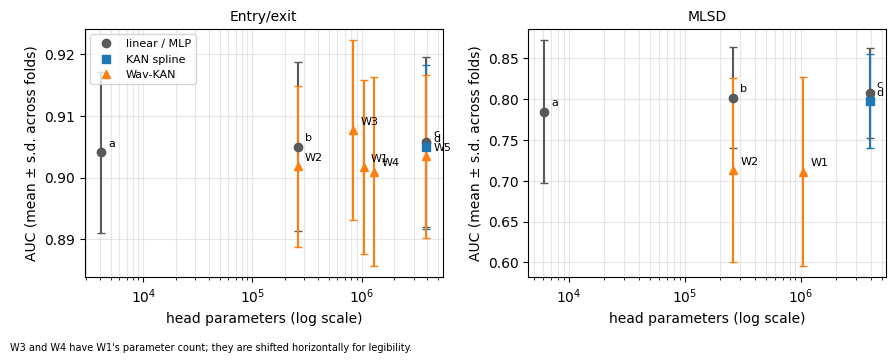

In [9]:
import matplotlib
import matplotlib.pyplot as plt
fig, axs = plt.subplots(1, 2, figsize=(9, 3.6))
ESTILO = {"a": ("o", "0.35"), "b": ("o", "0.35"), "c": ("o", "0.35"), "d": ("s", "tab:blue")}
for ax, t in zip(axs, TAREFAS):
    rr = RES[t]
    for i in rr.index:
        mk, cor = ESTILO.get(i, ("^", "tab:orange"))
        x, y, e = rr.loc[i, "params_cabeca"], rr.loc[i, f"{t}_auc_mean"], rr.loc[i, f"{t}_auc_std"]
        x = x * {"W3": 0.8, "W4": 1.25}.get(i, 1.0)   # W1, W3 e W4 têm o mesmo nº de parâmetros: afasta só no desenho
        ax.errorbar(x, y, yerr=e, fmt=mk, color=cor, capsize=3, ms=6)
        ax.annotate(i, (x, y), textcoords="offset points", xytext=(5, 4), fontsize=8)
    ax.set_xscale("log")
    ax.set_xlabel("head parameters (log scale)")
    ax.set_ylabel("AUC (mean ± s.d. across folds)")
    ax.set_title({"es": "Entry/exit", "dist": "MLSD"}[t], fontsize=10)
    ax.grid(alpha=0.3, which="both")
from matplotlib.lines import Line2D
axs[0].legend([Line2D([], [], marker=m, color=c, ls="") for m, c in (("o", "0.35"), ("s", "tab:blue"), ("^", "tab:orange"))],
              ["linear / MLP", "KAN spline", "Wav-KAN"], fontsize=8, loc="best")
fig.text(0.01, 0.01, "W3 and W4 have W1's parameter count; they are shifted horizontally for legibility.", fontsize=7)
fig.tight_layout(rect=(0, 0.04, 1, 1))
fig.savefig(R / "fig_auc_vs_parametros.pdf")
plt.show()

## 7. Diagnóstico dos pesos: scale/translation da Wav-KAN e grade da KAN spline

In [10]:
diag = pd.concat([cw.ler_diagnosticos(R, cw.EXPERIMENTO[t]).assign(tarefa=t) for t in TAREFAS], ignore_index=True)
if len(diag):
    diag["id"] = [ID[t].get(c) for t, c in zip(diag.tarefa, diag.config)]
    cols = ["scale_media", "scale_dp", "scale_abs_min", "frac_scale_na_guarda", "frac_scale_negativa",
            "translation_media", "translation_dp", "translation_min", "translation_max"]
    DIAG = diag.groupby(["tarefa", "id", "momento", "camada"])[cols].mean()
    DIAG.to_csv(R / "diagnostico_wavkan.csv")
    display(DIAG.round(4))
else:
    DIAG = pd.DataFrame()
    print("Sem diagnostico_wavkan.json ainda.")
for t in TAREFAS:
    k = [c for c in runs[t].columns if c.startswith("kan_")]
    if k:
        print(f"{ROTULO[t]} — KAN spline (d): fração das entradas dentro da grade base [−1, 1] no teste")
        display(runs[t][runs[t].id == "d"][k].mean().round(3))

scale_media  scale_dp  scale_abs_min  \
tarefa id momento   camada                                          
dist   W1 fim_fase1 camada0       0.9966    0.0132         0.9015   
                    camada1       0.9994    0.0155         0.9520   
          fim_fase2 camada0       0.9966    0.0133         0.9015   
                    camada1       0.9996    0.0156         0.9518   
       W2 fim_fase1 camada0       0.9966    0.0139         0.9034   
                    camada1       1.0027    0.0180         0.9565   
          fim_fase2 camada0       0.9966    0.0140         0.9033   
                    camada1       1.0030    0.0183         0.9558   
es     W1 fim_fase1 camada0       0.9952    0.0149         0.8789   
                    camada1       0.9977    0.0162         0.9471   
          fim_fase2 camada0       0.9951    0.0149         0.8787   
                    camada1       0.9978    0.0162         0.9470   
       W2 fim_fase1 camada0       0.9951    0.0153         0.8832   
                    camada1       1.0025    0.0196         0.9541   
          fim_fase2 camada0       0.9951    0.0154         0.8834   
                    camada1       1.0026    0.0196         0.9549   
       W3 fim_fase1 camada0       0.9952    0.0148         0.8876   
                    camada1       0.9927    0.0175         0.9458   
          fim_fase2 camada0       0.9952    0.0148         0.8872   
                    camada1       0.9925    0.0177         0.9447   
       W4 fim_fase1 camada0       0.9952    0.0135         0.8928   
                    camada1       0.9941    0.0141         0.9571   
          fim_fase2 camada0       0.9952    0.0135         0.8929   
                    camada1       0.9941    0.0141         0.9573   
       W5 fim_fase1 camada0       0.9952    0.0150         0.8686   
                    camada1       0.9949    0.0166         0.9310   
          fim_fase2 camada0       0.9952    0.0150         0.8684   
                    camada1       0.9949    0.0166         0.9310   

                             frac_scale_na_guarda  frac_scale_negativa  \
tarefa id momento   camada                                               
dist   W1 fim_fase1 camada0                   0.0                  0.0   
                    camada1                   0.0                  0.0   
          fim_fase2 camada0                   0.0                  0.0   
                    camada1                   0.0                  0.0   
       W2 fim_fase1 camada0                   0.0                  0.0   
                    camada1                   0.0                  0.0   
          fim_fase2 camada0                   0.0                  0.0   
                    camada1                   0.0                  0.0   
es     W1 fim_fase1 camada0                   0.0                  0.0   
                    camada1                   0.0                  0.0   
          fim_fase2 camada0                   0.0                  0.0   
                    camada1                   0.0                  0.0   
       W2 fim_fase1 camada0                   0.0                  0.0   
                    camada1                   0.0                  0.0   
          fim_fase2 camada0                   0.0                  0.0   
                    camada1                   0.0                  0.0   
       W3 fim_fase1 camada0                   0.0                  0.0   
                    camada1                   0.0                  0.0   
          fim_fase2 camada0                   0.0                  0.0   
                    camada1                   0.0                  0.0   
       W4 fim_fase1 camada0                   0.0                  0.0   
                    camada1                   0.0                  0.0   
          fim_fase2 camada0                   0.0                  0.0   
                    camada1                   0.0                  0.0   
       W5 fim_fase1 camada0       

entrada/saída — KAN spline (d): fração das entradas dentro da grade base [−1, 1] no teste


,0
kan_es.kan0_frac_base,0.976
kan_es.kan1_frac_base,0.545


MLSD (distância) — KAN spline (d): fração das entradas dentro da grade base [−1, 1] no teste


,0
kan_dist.kan0_frac_base,0.973
kan_dist.kan1_frac_base,0.502


## 8. Decisão e frases (EN para o manuscrito, PT para a dissertação)

In [11]:
def fmt(t, i, m="auc"):
    r = RES[t].loc[i]
    return f"{r[f'{t}_{m}_mean']:.3f} ± {r[f'{t}_{m}_std']:.3f}"

def mp(n):
    return f"{n / 1e6:.2f} M" if n >= 1e5 else f"{n:,}"

def ressalva(c, en=True):
    if len(c["sementes"]) < 2:
        return " (single training seed)" if en else " (uma única semente de treino)"
    return f" (seeds {', '.join(map(str, c['sementes']))})" if en else f" (sementes {', '.join(map(str, c['sementes']))})"

def ic(c, m="auc"):
    lo, hi = c[f"ic95_{m}"]
    return f"Δ{'AUC' if m == 'auc' else 'F1'} = {c[f'delta_{m}_oof']:+.3f}, 95% CI [{lo:+.3f}, {hi:+.3f}]"

REF_EN = {"b": "an MLP head of the same size", "c": "a parameter-matched MLP head", "d": "the spline-KAN head"}
REF_PT = {"b": "a uma cabeça MLP do mesmo tamanho", "c": "a uma cabeça MLP isoparamétrica", "d": "à cabeça KAN spline"}
FR_EN, FR_PT = [], []
for t in TAREFAS:
    c = COMP.get(f"{t}__W2_vs_b")
    if c is not None:
        d, p2, pb = DESFECHO[t], RES[t].loc["W2", "params_cabeca"], RES[t].loc["b", "params_cabeca"]
        base = (f"On {TASK_EN[t]}, under an identical protocol, a wavelet-KAN head (Mexican hat, {mp(p2)} parameters)")
        num = f"AUC {fmt(t, 'W2')} vs. {fmt(t, 'b')}; {ic(c)}; better in {c['dobras_a_vence']}/{c['n_dobras']} folds"
        FR_EN.append(base + {
            "A": f" outperformed an MLP head of the same size ({mp(pb)}; {num}){ressalva(c)}; at this budget it is more parameter-efficient than an MLP.",
            "B": f" performed on par with an MLP head of the same size ({mp(pb)}; {num}; within the pre-registered non-inferiority margin of {MARGEM_NI:+.2f}){ressalva(c)}.",
            "C": f" underperformed an MLP head of the same size ({mp(pb)}; {num}){ressalva(c)}.",
            "inconclusivo": f" was not shown non-inferior to an MLP head of the same size ({mp(pb)}; {num}; the lower CI bound is below the pre-registered {MARGEM_NI:+.2f} margin), although the pre-registered rule for a difference (≥ 4/5 folds and CI excluding zero) was not met either{ressalva(c)}.",
        }[d])
        base_pt = f"Em {ROTULO[t]}, no mesmo protocolo, uma cabeça Wav-KAN (chapéu mexicano, {mp(p2)} parâmetros)"
        num_pt = f"AUC {fmt(t, 'W2')} contra {fmt(t, 'b')}; {ic(c).replace('95% CI', 'IC 95 %')}; melhor em {c['dobras_a_vence']}/{c['n_dobras']} dobras"
        FR_PT.append(base_pt + {
            "A": f" superou uma cabeça MLP do mesmo tamanho ({mp(pb)}; {num_pt}){ressalva(c, False)}; nesse orçamento, ela é mais eficiente em parâmetros que uma MLP.",
            "B": f" empatou com uma cabeça MLP do mesmo tamanho ({mp(pb)}; {num_pt}; dentro da margem de não inferioridade pré-registrada de {MARGEM_NI:+.2f}){ressalva(c, False)}.",
            "C": f" ficou abaixo de uma cabeça MLP do mesmo tamanho ({mp(pb)}; {num_pt}){ressalva(c, False)}.",
            "inconclusivo": f" não se mostrou não inferior a uma cabeça MLP do mesmo tamanho ({mp(pb)}; {num_pt}; o limite inferior do IC fica abaixo da margem pré-registrada de {MARGEM_NI:+.2f}), mas a regra pré-registrada para uma diferença (≥ 4/5 dobras e IC sem o zero) também não foi cumprida{ressalva(c, False)}.",
        }[d])
    for a, b in (("W1", "c"), ("W5", "c"), ("W1", "d"), ("W2", "d"), ("W5", "d")):
        c = COMP.get(f"{t}__{a}_vs_{b}")
        if c is None:
            continue
        pa, pref = RES[t].loc[a, "params_cabeca"], RES[t].loc[b, "params_cabeca"]
        cab_en = f"A wavelet-KAN head ({a}: Mexican hat, {mp(pa)} parameters)"
        cab_pt = f"Uma cabeça Wav-KAN ({a}: chapéu mexicano, {mp(pa)} parâmetros)"
        if c["nao_inferior"]:
            FR_EN.append(f"On {TASK_EN[t]}, {cab_en[0].lower() + cab_en[1:]} matched {REF_EN[b]} ({mp(pref)}) within the pre-registered "
                         f"non-inferiority margin ({ic(c)}; {ic(c, 'f1')}){ressalva(c)}.")
            FR_PT.append(f"Em {ROTULO[t]}, {cab_pt[0].lower() + cab_pt[1:]} foi não inferior {REF_PT[b]} ({mp(pref)}) dentro da margem "
                         f"pré-registrada ({ic(c).replace('95% CI', 'IC 95 %')}; {ic(c, 'f1').replace('95% CI', 'IC 95 %')}){ressalva(c, False)}.")
        else:
            FR_EN.append(f"On {TASK_EN[t]}, {cab_en[0].lower() + cab_en[1:]} did not reach non-inferiority against {REF_EN[b]} ({mp(pref)}; "
                         f"{ic(c)}; {ic(c, 'f1')}){ressalva(c)}.")
            FR_PT.append(f"Em {ROTULO[t]}, {cab_pt[0].lower() + cab_pt[1:]} não atingiu a não inferioridade em relação {REF_PT[b]} ({mp(pref)}; "
                         f"{ic(c).replace('95% CI', 'IC 95 %')}; {ic(c, 'f1').replace('95% CI', 'IC 95 %')}){ressalva(c, False)}.")
for k, x in TEMPO.items():
    t, a, b = x["tarefa"], x["a"], x["b"]
    if (a, b) not in (("W2", "b"), ("W1", "d")):
        continue
    ma, _, mb, _ = x["min_por_dobra"]
    razao = x["razao_params_cabeca"]
    ref_en, ref_pt = {"b": ("the MLP-128 head", "a MLP-128"), "d": ("the spline-KAN head", "a KAN spline")}[b]
    if 0.95 <= razao <= 1.05:
        menos, menos_pt = f"the same head-parameter budget as {ref_en}", f"o mesmo orçamento de parâmetros na cabeça que {ref_pt}"
    else:
        menos = f"{razao:.1f}× fewer head parameters than {ref_en}" if razao > 1 else f"{1 / razao:.1f}× more head parameters than {ref_en}"
        menos_pt = (f"{razao:.1f}× menos parâmetros na cabeça que {ref_pt}" if razao > 1
                    else f"{1 / razao:.1f}× mais parâmetros na cabeça que {ref_pt}")
    FR_EN.append(f"On {TASK_EN[t]}, {a} has {menos} " + {
        "mais_rapida": f"and trains faster ({ma:.1f} vs. {mb:.1f} min per fold on an NVIDIA L4).",
        "igual": f"at equal wall-clock time ({ma:.1f} vs. {mb:.1f} min per fold on an NVIDIA L4); the ResNet-152 backbone dominates the cost.",
        "mais_lenta": f"but trains {x['variacao_dobra_pct']:.0f}% slower per fold ({ma:.1f} vs. {mb:.1f} min on an NVIDIA L4), "
                      "because each wavelet layer materialises a batch × output × input tensor.",
        "indefinido": f"({ma:.1f} vs. {mb:.1f} min per fold on an NVIDIA L4; the head-only benchmark shows no speed-up, "
                      "so the difference is attributed to machine variation).",
    }[x["desfecho"]])
    FR_PT.append(f"Em {ROTULO[t]}, a {a} tem {menos_pt} " + {
        "mais_rapida": f"e treina mais rápido ({ma:.1f} contra {mb:.1f} min por dobra na L4).",
        "igual": f"com o mesmo tempo de treino ({ma:.1f} contra {mb:.1f} min por dobra na L4); o backbone ResNet-152 domina o custo.",
        "mais_lenta": f"mas treina {x['variacao_dobra_pct']:.0f}% mais devagar por dobra ({ma:.1f} contra {mb:.1f} min na L4), "
                      "porque cada camada com wavelets materializa um tensor lote × saída × entrada.",
        "indefinido": f"({ma:.1f} contra {mb:.1f} min por dobra na L4; o tempo só da cabeça não mostra ganho, "
                      "então a diferença é atribuída à variação entre máquinas).",
    }[x["desfecho"]])

pode = {
    "more_parameter_efficient_than_an_MLP": {t: DESFECHO.get(t) == "A" for t in TAREFAS},
    "wavkan_faster": {k: v["desfecho"] == "mais_rapida" for k, v in TEMPO.items()},
    "compare_with_0.908_or_0.893": False,
    "spline_KAN_is_the_reference_that_works": False,
}
decisao = {"margem_ni": MARGEM_NI, "n_boot": N_BOOT, "desfecho_contraste_1": DESFECHO, "contrastes": COMP, "tempo": TEMPO,
           "pode_afirmar": pode, "sementes_por_config": {t: {ID[t][c]: s for c, s in SEM[t].items()} for t in TAREFAS},
           "avisos": avisos, "frases_en": FR_EN, "frases_pt": FR_PT,
           "plugin_sha256": SHA_PLUGIN_ESPERADO, "protocolo_sha256": SHA_PROTOCOLO_ESPERADO}
pc.gravar_json_atomico(decisao, R / "decisao_wavkan.json")
texto = ("# Frases da Wav-KAN (geradas pelo 08)\n\n## EN (manuscrito)\n\n" + "\n\n".join(f"- {f}" for f in FR_EN)
         + "\n\n## PT (dissertação)\n\n" + "\n\n".join(f"- {f}" for f in FR_PT)
         + f"\n\n## Pode afirmar\n\n```json\n{json.dumps(pode, indent=1, ensure_ascii=False)}\n```\n"
         + "\n## Lembretes\n\n- Não comparar com 0,908 (TCC antigo) nem com 0,893 (artigo do SIBGRAPI): protocolos diferentes.\n"
         + "- O contraste que mais informa é contra a melhor MLP do mesmo orçamento; a KAN spline (d) empata com as MLPs em E/S e fica abaixo da MLP-iso na MLSD.\n"
         + "- Uma vantagem da Wav-KAN pode vir de `translation`/`scale` se ajustarem à faixa das features (≥ 0, várias acima de 1), e não \"das wavelets\": veja `diagnostico_wavkan.csv` e a fração dentro da grade da spline.\n"
         + "- Citar Lira et al. (2025) como origem da base; nenhuma imagem sai da sessão.\n")
(R / "frases_wavkan.md").write_text(texto, encoding="utf-8")
print(texto)

# Frases da Wav-KAN (geradas pelo 08)

## EN (manuscrito)

- On entry/exit classification, under an identical protocol, a wavelet-KAN head (Mexican hat, 0.26 M parameters) was not shown non-inferior to an MLP head of the same size (0.26 M; AUC 0.902 ± 0.013 vs. 0.905 ± 0.014; ΔAUC = -0.001, 95% CI [-0.004, +0.002]; better in 0/5 folds; the lower CI bound is below the pre-registered -0.02 margin), although the pre-registered rule for a difference (≥ 4/5 folds and CI excluding zero) was not met either (seeds 42, 43, 44).

- On entry/exit classification, a wavelet-KAN head (W1: Mexican hat, 1.05 M parameters) matched a parameter-matched MLP head (3.94 M) within the pre-registered non-inferiority margin (ΔAUC = -0.002, 95% CI [-0.005, +0.002]; ΔF1 = -0.003, 95% CI [-0.014, +0.008]) (seeds 42, 43, 44).

- On entry/exit classification, a wavelet-KAN head (W5: Mexican hat, 3.94 M parameters) matched a parameter-matched MLP head (3.94 M) within the pre-registered non-inferiority margin (ΔAUC =